# 01 - Exploratory data analysis

Distributions, time patterns, funnel, cohorts and revenue concentration. Figures are produced by `ecom eda` (`src/ecom/analysis/eda.py`).

In [1]:
import json
import pandas as pd
from IPython.display import Image, Markdown, display
from ecom.config import get_config
from ecom.layout import outputs_dir, table_path
cfg = get_config()
OUT = outputs_dir(cfg)
FIG = cfg.paths.figures
pd.set_option("display.float_format", "{:,.4f}".format)
print(f"source={cfg.source} sample={cfg.sample_rate:.0%} outputs={OUT}")

source=synthetic sample=100% outputs=D:\smaiproj\data\outputs\synthetic\full


## Headline KPIs (Spark SQL `kpis.sql`)

In [2]:
pd.read_csv(OUT / "overview.csv").T

,0
events,11812515
users,384820
sessions,2034694
products,29993
purchases,170303
revenue,"32,190,401.7300"
buyers,63837
session_conversion,0.0755
user_conversion,0.1659
first_date,2019-10-01


## Ad-hoc SQL with DuckDB straight on the silver Parquet

In [3]:
from ecom.stats.hypothesis_tests import connect
con = connect(cfg)
con.execute('''
    SELECT brand, COUNT(*) AS purchases, ROUND(SUM(price)) AS revenue
    FROM events_clean WHERE event_type = 'purchase' AND brand <> 'unknown'
    GROUP BY brand ORDER BY revenue DESC LIMIT 10
''').df()

,brand,purchases,revenue
0,samsung,33496,"6,549,223.0000"
1,apple,10234,"3,001,858.0000"
2,hp,3957,"2,211,807.0000"
3,xiaomi,10420,"1,792,930.0000"
4,lg,4712,"1,433,717.0000"
5,lenovo,1973,"1,177,695.0000"
6,ratalo,17401,"934,362.0000"
7,huawei,2938,"612,053.0000"
8,bosch,2697,"610,203.0000"
9,ratane,5908,"472,517.0000"


## Distributions (log scale)

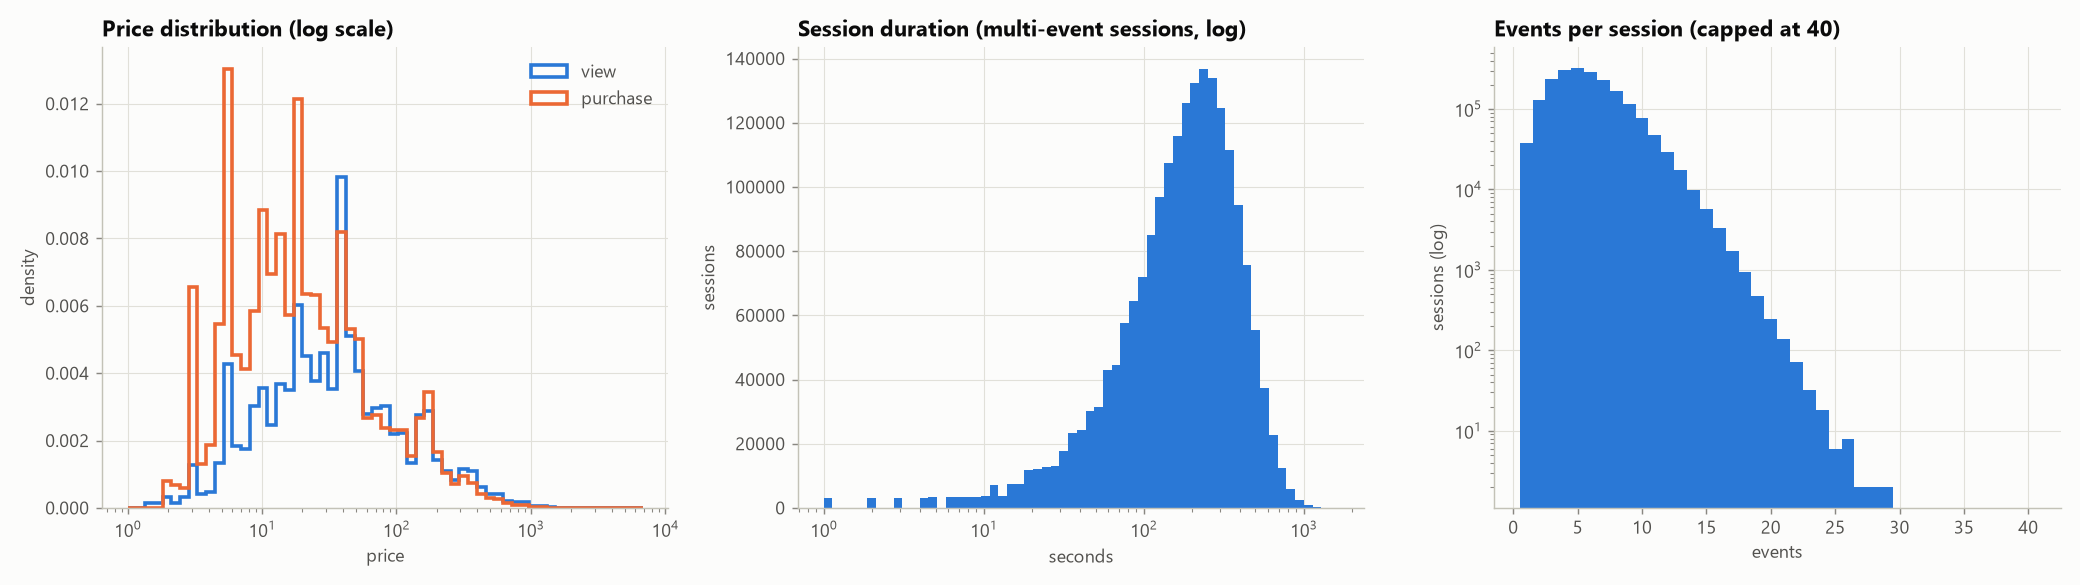

In [4]:
display(Image(FIG / "eda_distributions.png"))

## When do people shop?

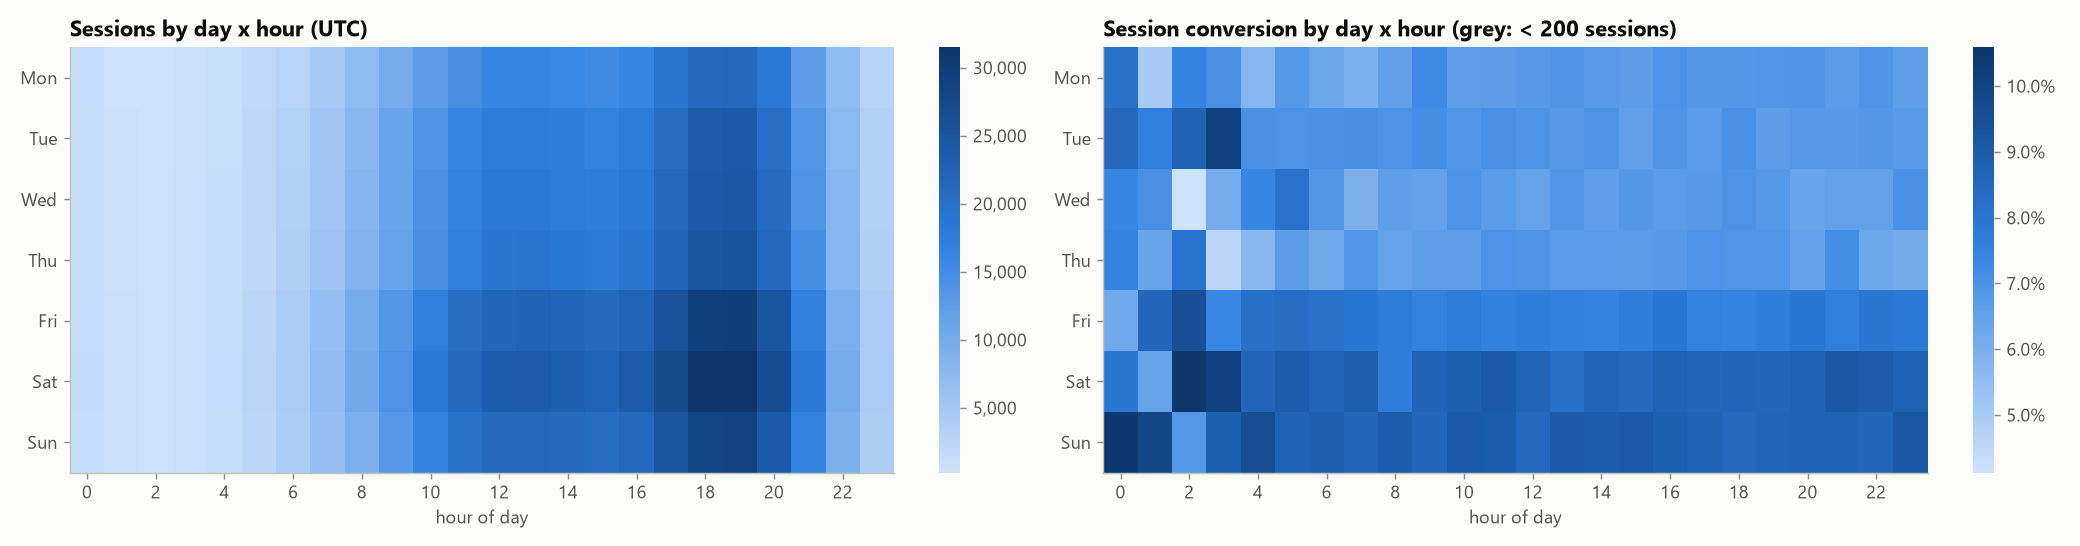

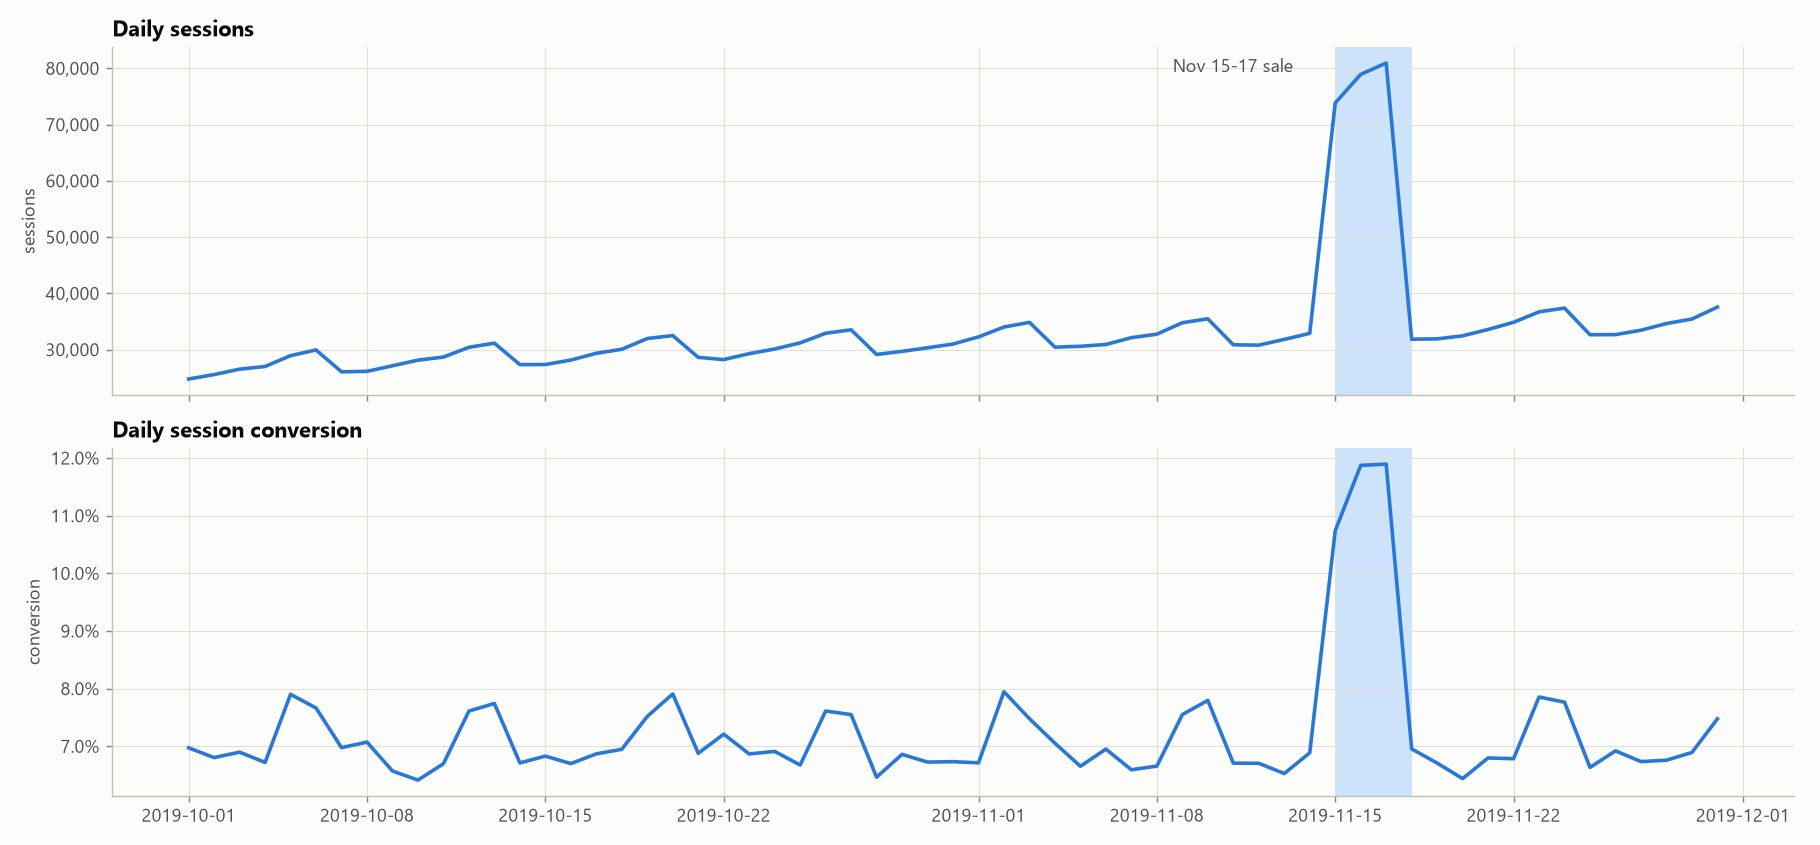

In [5]:
display(Image(FIG / "eda_hour_dow.png"))
display(Image(FIG / "eda_daily.png"))

## Funnel and cohorts

,stage_order,stage,users,pct_of_viewers,step_conversion
0,1,view,384820,1.0000,NaN
1,2,cart,119672,0.3110,0.3110
2,3,purchase,63826,0.1659,0.5333


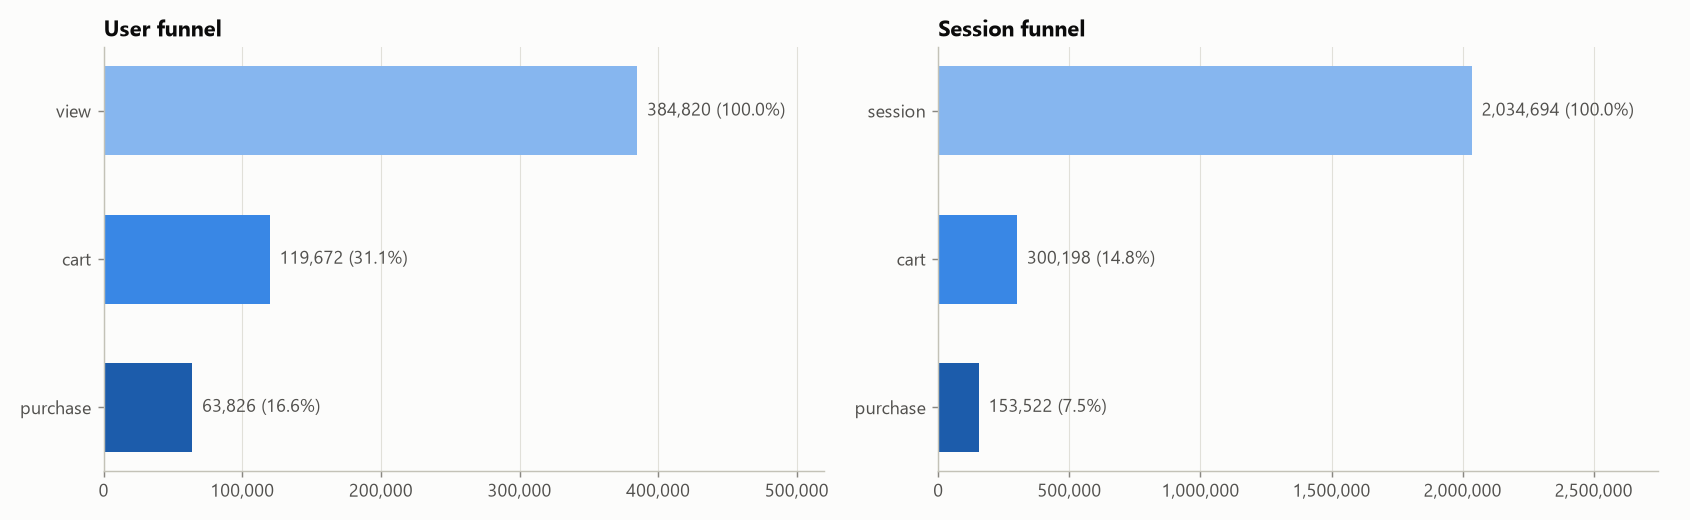

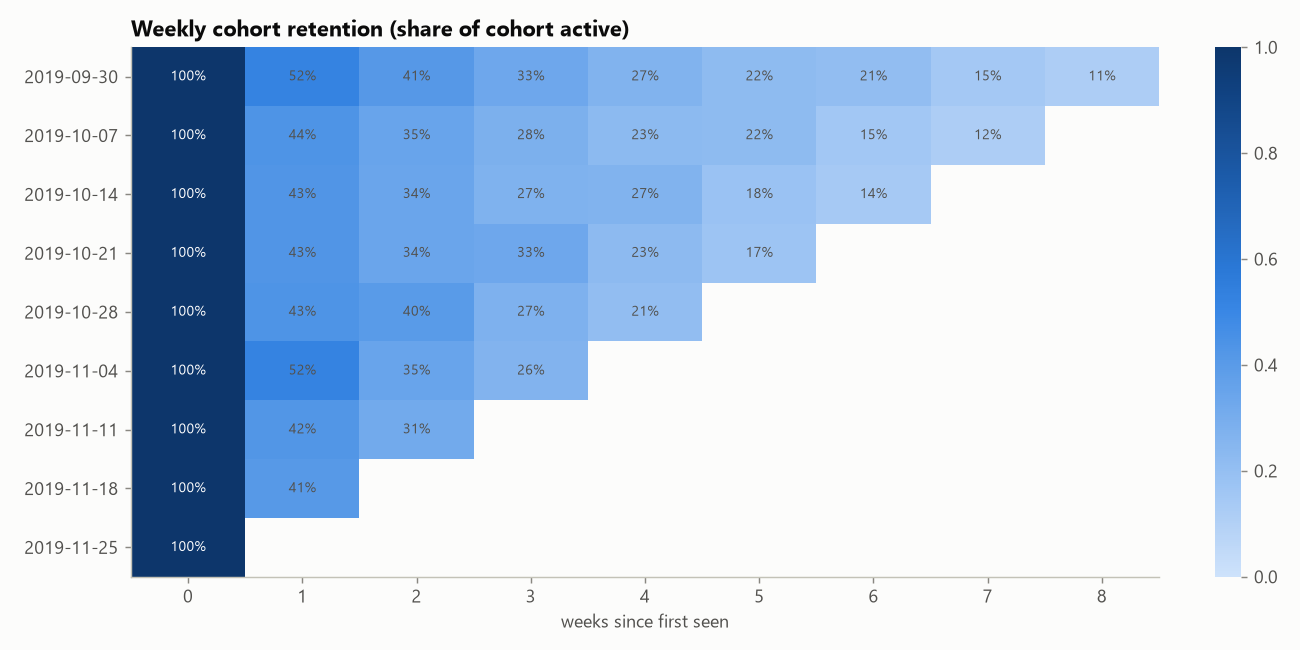

In [6]:
display(pd.read_csv(OUT / "funnel_overall.csv"))
display(Image(FIG / "eda_funnel.png"))
display(Image(FIG / "eda_cohorts.png"))

## Revenue concentration

,top_0_1pct_share,top_1pct_share,top_10pct_share,buyer_share
0,0.1070,0.3931,0.9465,0.1659


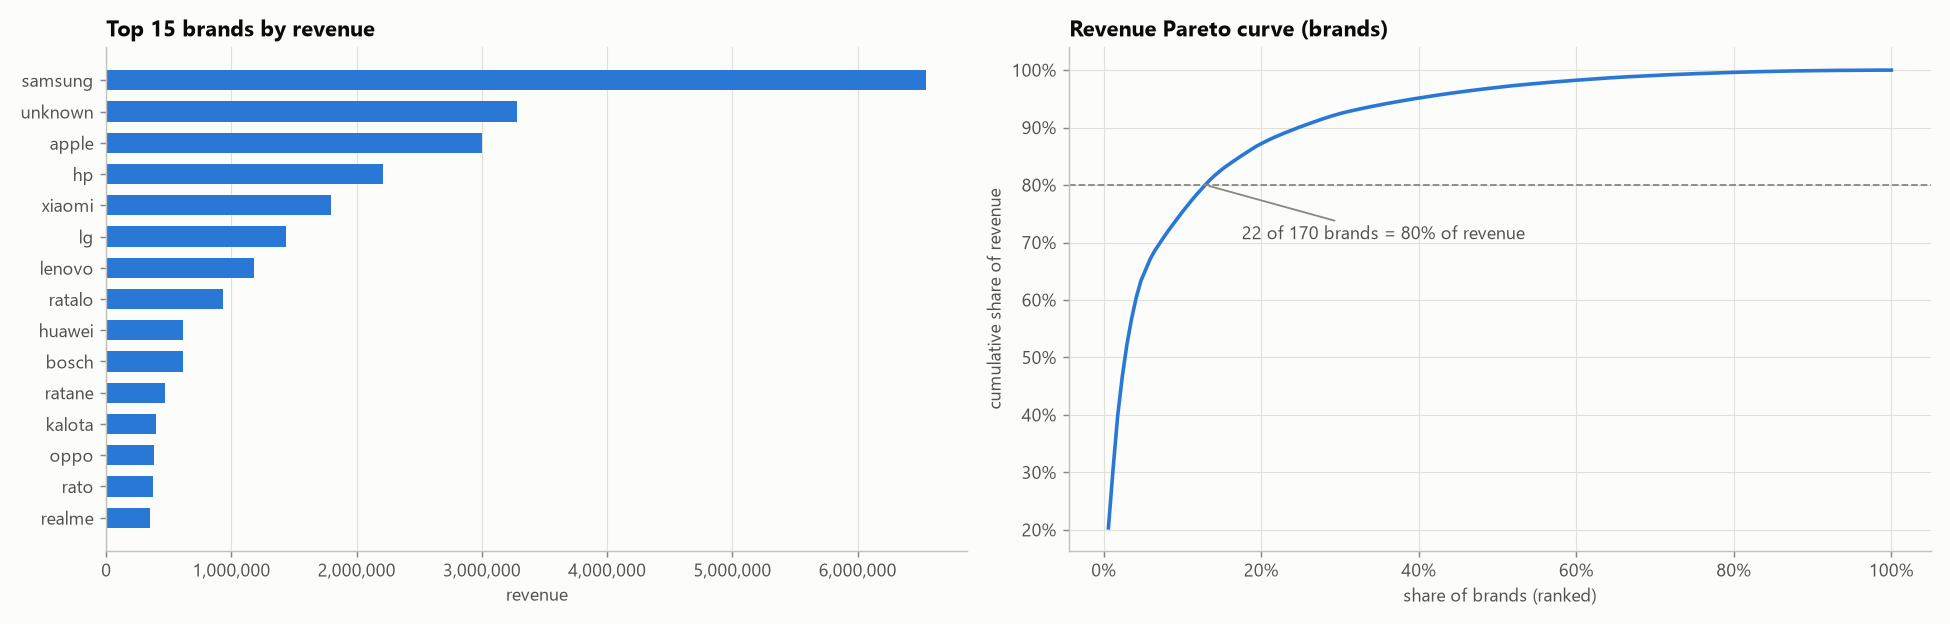

In [7]:
display(pd.read_csv(OUT / "revenue_concentration.csv"))
display(Image(FIG / "eda_pareto.png"))

## Insights

In [8]:
ins = json.loads((OUT / "eda_insights.json").read_text())["insights"]
display(Markdown("\n".join(f"{i}. {s}" for i, s in enumerate(ins, 1))))

1. The top 1% of users generate 39% of revenue and the top 10% generate 95%; only 16.6% of visitors buy anything in two months.
2. 31% of viewers ever add to cart, and 53% of those go on to buy - the view-to-cart step is where most users are lost.
3. Sessions convert at 7.5%; half of all multi-event sessions last under 3.1 minutes and 2% of sessions are a single page view.
4. The Nov 15-17 sale lifted daily traffic 2.5x and conversion from 7.0% to 11.5%.
5. Electronics drives 50% of revenue; computers.notebook has the highest average order value (679).
6. Revenue is concentrated in brands too: 22 of 170 brands (13%) make up 80% of it.
7. Buyers pay a median 120 per item vs a median 162 for viewed items, so cheaper items convert better.
8. Only 44% of a weekly cohort comes back the next week; traffic peaks at 19:00 UTC.